In [1]:
# # 1. Install the library
# %pip install opendatasets

# # 2. Import and download using the dataset URL
# import opendatasets as od

# dataset_url = "https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data?select=train.csv"
# od.download(dataset_url)

  Using cached opendatasets-0.1.22-py3-none-any.whl.metadata (9.2 kB)
  Using cached kaggle-2.2.5-py3-none-any.whl.metadata (17 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
  Using cached jupytext-1.19.6-py3-none-any.whl.metadata (15 kB)
  Using cached kagglesdk-0.1.38-py3-none-any.whl.metadata (13 kB)
  Using cached protobuf-7.36.2-cp310-abi3-manylinux2014_x86_64.whl.metadata (595 bytes)
  Using cached python_dotenv-1.2.4-py3-none-any.whl.metadata (29 kB)
  Using cached python_slugify-9.1.3-py3-none-any.whl.metadata (12 kB)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdit_py_plugins-0.6.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
  Using cached text_unidecode-1.3-py2.py3-none-any.whl.metadata (2.4 kB)
Using cached opendatasets-0.1.22-py3-none-any.whl (15 kB)
Using cached kaggle-2.2.5-py3-none-any.whl (140 kB)
Using cached kagglesdk-0.1.38-py3-none-any.whl (290 k

ModuleNotFoundError: No module named 'cgi'

In [1]:
%pip install kagglehub

import kagglehub

# Download latest version
path = kagglehub.competition_download('store-sales-time-series-forecasting')

print("Path to competition files:", path)



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /usr/local/python/3.14.2/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Path to competition files: /home/codespace/.cache/kagglehub/competitions/store-sales-time-series-forecasting


In [2]:
import os
import pandas as pd

DATA_DIR = "/home/codespace/.cache/kagglehub/competitions/store-sales-time-series-forecasting"

# Verify directory contents
print("Files available:", os.listdir(DATA_DIR))

# Load core datasets
df_full_train = pd.read_csv(f"{DATA_DIR}/train.csv", parse_dates=["date"])
df_test = pd.read_csv(f"{DATA_DIR}/test.csv", parse_dates=["date"])
df_stores = pd.read_csv(f"{DATA_DIR}/stores.csv")
df_oil = pd.read_csv(f"{DATA_DIR}/oil.csv", parse_dates=["date"])
df_holidays = pd.read_csv(f"{DATA_DIR}/holidays_events.csv", parse_dates=["date"])
df_transactions = pd.read_csv(f"{DATA_DIR}/transactions.csv", parse_dates=["date"])

Files available: ['test.csv', 'oil.csv', 'transactions.csv', 'train.csv', 'holidays_events.csv', 'stores.csv', 'sample_submission.csv']


In [ ]:
# Data cleaning, JOIN tables

In [3]:
# Predict sales
df_full_train.dtypes
df_full_train.nunique()
# df_full_train.isnull().sum()

id             3000888
date              1684
store_nbr           54
family              33
sales           379610
onpromotion        362
dtype: int64

In [6]:
df_full_train[df_full_train['sales'] > 0.0]

,id,date,store_nbr,family,sales,onpromotion
563,563,2013-01-01,25,BEAUTY,2.000,0
564,564,2013-01-01,25,BEVERAGES,810.000,0
566,566,2013-01-01,25,BREAD/BAKERY,180.589,0
568,568,2013-01-01,25,CLEANING,186.000,0
569,569,2013-01-01,25,DAIRY,143.000,0
...,...,...,...,...,...,...
3000883,3000883,2017-08-15,9,POULTRY,438.133,0
3000884,3000884,2017-08-15,9,PREPARED FOODS,154.553,1
3000885,3000885,2017-08-15,9,PRODUCE,2419.729,148
3000886,3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,8


In [20]:
df_test.head()
# df_test.isnull().sum()

,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


In [6]:
# join on date, with type (holiday/ event/etc), locale (national/local/other)
df_holidays.head()
# df_holidays.nunique()

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [11]:
df_transactions.head()
# df_transactions.isnull().sum()

,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


In [16]:
# join with store_nbr with cluster
df_stores.head() # cluster is a group of similar store
# df_stores.isnull().sum()

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [18]:
print("Oil duplicate dates:", df_oil['date'].duplicated().sum())
print(df_oil.isnull().sum())

Oil duplicate dates: 0
date          0
dcoilwtico    0
dtype: int64


In [4]:
# df_oil.isnull().sum() # null 43
# join on date with dcoilwtico
df_oil['dcoilwtico'] = df_oil['dcoilwtico'].fillna(df_oil['dcoilwtico'].mean()) # fill in with mean
df_oil.head()

,date,dcoilwtico
0,2013-01-01,67.714366
1,2013-01-02,93.140000
2,2013-01-03,92.970000
3,2013-01-04,93.120000
4,2013-01-07,93.200000


In [5]:
df_full_train['date'] = pd.to_datetime(df_full_train['date'])
df_oil['date'] = pd.to_datetime(df_oil['date'])
df_transactions['date'] = pd.to_datetime(df_transactions['date'])
df_holidays['date'] = pd.to_datetime(df_holidays['date'])

In [6]:
df_full_train = df_full_train.merge(
    df_oil,
    on='date',
    how='left',
    validate='many_to_one'
)

In [7]:
df_full_train = df_full_train.merge(
    df_transactions,
    on=['date', 'store_nbr'],
    how='left',
    validate='many_to_one'
)

In [8]:
df_full_train.head()

,id,date,store_nbr,family,sales,onpromotion,dcoilwtico,transactions
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,67.714366,NaN
1,1,2013-01-01,1,BABY CARE,0.0,0,67.714366,NaN
2,2,2013-01-01,1,BEAUTY,0.0,0,67.714366,NaN
3,3,2013-01-01,1,BEVERAGES,0.0,0,67.714366,NaN
4,4,2013-01-01,1,BOOKS,0.0,0,67.714366,NaN


In [9]:
df_full_train.isnull().sum()

id                   0
date                 0
store_nbr            0
family               0
sales                0
onpromotion          0
dcoilwtico      857142
transactions    245784
dtype: int64

In [16]:
df_full_train = df_full_train.merge(
    df_stores,
    on='store_nbr',
    how='left',
    validate='many_to_one'
)

df_full_train.head()

,id,date,store_nbr,family,sales,onpromotion,dcoilwtico,transactions,city,state,type,cluster
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,67.714366,NaN,Quito,Pichincha,D,13
1,1,2013-01-01,1,BABY CARE,0.0,0,67.714366,NaN,Quito,Pichincha,D,13
2,2,2013-01-01,1,BEAUTY,0.0,0,67.714366,NaN,Quito,Pichincha,D,13
3,3,2013-01-01,1,BEVERAGES,0.0,0,67.714366,NaN,Quito,Pichincha,D,13
4,4,2013-01-01,1,BOOKS,0.0,0,67.714366,NaN,Quito,Pichincha,D,13


In [11]:
store_locations = df_stores[
    ['store_nbr', 'city', 'state']
]

national = df_holidays[
    df_holidays['locale'] == 'National'
].merge(
    store_locations[['store_nbr']],
    how='cross'
)

regional = df_holidays[
    df_holidays['locale'] == 'Regional'
].merge(
    store_locations,
    left_on='locale_name',
    right_on='state'
)

local = df_holidays[
    df_holidays['locale'] == 'Local'
].merge(
    store_locations,
    left_on='locale_name',
    right_on='city'
)

applicable_holidays = pd.concat(
    [national, regional, local],
    ignore_index=True
)

applicable_holidays.tail()

,date,type,locale,locale_name,description,transferred,store_nbr,city,state
9945,2017-12-08,Transfer,Local,Quito,Traslado Fundacion de Quito,False,46,Quito,Pichincha
9946,2017-12-08,Transfer,Local,Quito,Traslado Fundacion de Quito,False,47,Quito,Pichincha
9947,2017-12-08,Transfer,Local,Quito,Traslado Fundacion de Quito,False,48,Quito,Pichincha
9948,2017-12-08,Transfer,Local,Quito,Traslado Fundacion de Quito,False,49,Quito,Pichincha
9949,2017-12-22,Holiday,Local,Salinas,Cantonizacion de Salinas,False,25,Salinas,Santa Elena


In [12]:
holiday_features = (
    applicable_holidays
    .groupby(['date', 'store_nbr'])
    .agg({
        'type': lambda x: list(x.unique()),
        'locale': lambda x: list(x.unique()),
        'transferred': 'max'
    })
    .reset_index()
)
# holiday_features.head()
df_full_train = df_full_train.merge(
    holiday_features,
    on=['date', 'store_nbr'],
    how='left',
    validate='many_to_one'
)

df_full_train[df_full_train['date'] == '2013-01-01']

,id,date,store_nbr,family,sales,onpromotion,dcoilwtico,transactions,type,locale,transferred
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,67.714366,NaN,[Holiday],[National],False
1,1,2013-01-01,1,BABY CARE,0.0,0,67.714366,NaN,[Holiday],[National],False
2,2,2013-01-01,1,BEAUTY,0.0,0,67.714366,NaN,[Holiday],[National],False
3,3,2013-01-01,1,BEVERAGES,0.0,0,67.714366,NaN,[Holiday],[National],False
4,4,2013-01-01,1,BOOKS,0.0,0,67.714366,NaN,[Holiday],[National],False


In [13]:
df_full_train[df_full_train['date'] == '2013-01-01']

,id,date,store_nbr,family,sales,onpromotion,dcoilwtico,transactions,type,locale,transferred
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,67.714366,NaN,[Holiday],[National],False
1,1,2013-01-01,1,BABY CARE,0.0,0,67.714366,NaN,[Holiday],[National],False
2,2,2013-01-01,1,BEAUTY,0.0,0,67.714366,NaN,[Holiday],[National],False
3,3,2013-01-01,1,BEVERAGES,0.0,0,67.714366,NaN,[Holiday],[National],False
4,4,2013-01-01,1,BOOKS,0.0,0,67.714366,NaN,[Holiday],[National],False
...,...,...,...,...,...,...,...,...,...,...,...
1777,1777,2013-01-01,9,POULTRY,0.0,0,67.714366,NaN,[Holiday],[National],False
1778,1778,2013-01-01,9,PREPARED FOODS,0.0,0,67.714366,NaN,[Holiday],[National],False
1779,1779,2013-01-01,9,PRODUCE,0.0,0,67.714366,NaN,[Holiday],[National],False
1780,1780,2013-01-01,9,SCHOOL AND OFFICE SUPPLIES,0.0,0,67.714366,NaN,[Holiday],[National],False


In [10]:
print(applicable_holidays.columns.tolist())


['date', 'type_x', 'locale', 'locale_name', 'description', 'transferred', 'store_nbr', 'city', 'state', 'type_y', 'cluster']


In [24]:
df_full_train.head()

,id,date,store_nbr,family,sales,onpromotion,dcoilwtico,transactions,city_x,state_x,...,city_y,state_y,type_y,cluster_y,holiday_Additional,holiday_Bridge,holiday_Event,holiday_Holiday,holiday_Transfer,holiday_Work Day
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,67.714366,NaN,Quito,Pichincha,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,1.0,0.0,0.0
1,1,2013-01-01,1,BABY CARE,0.0,0,67.714366,NaN,Quito,Pichincha,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,1.0,0.0,0.0
2,2,2013-01-01,1,BEAUTY,0.0,0,67.714366,NaN,Quito,Pichincha,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,1.0,0.0,0.0
3,3,2013-01-01,1,BEVERAGES,0.0,0,67.714366,NaN,Quito,Pichincha,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,1.0,0.0,0.0
4,4,2013-01-01,1,BOOKS,0.0,0,67.714366,NaN,Quito,Pichincha,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,1.0,0.0,0.0


In [3]:
# EDA
import matplotlib.pyplot as plt
import seaborn as sns

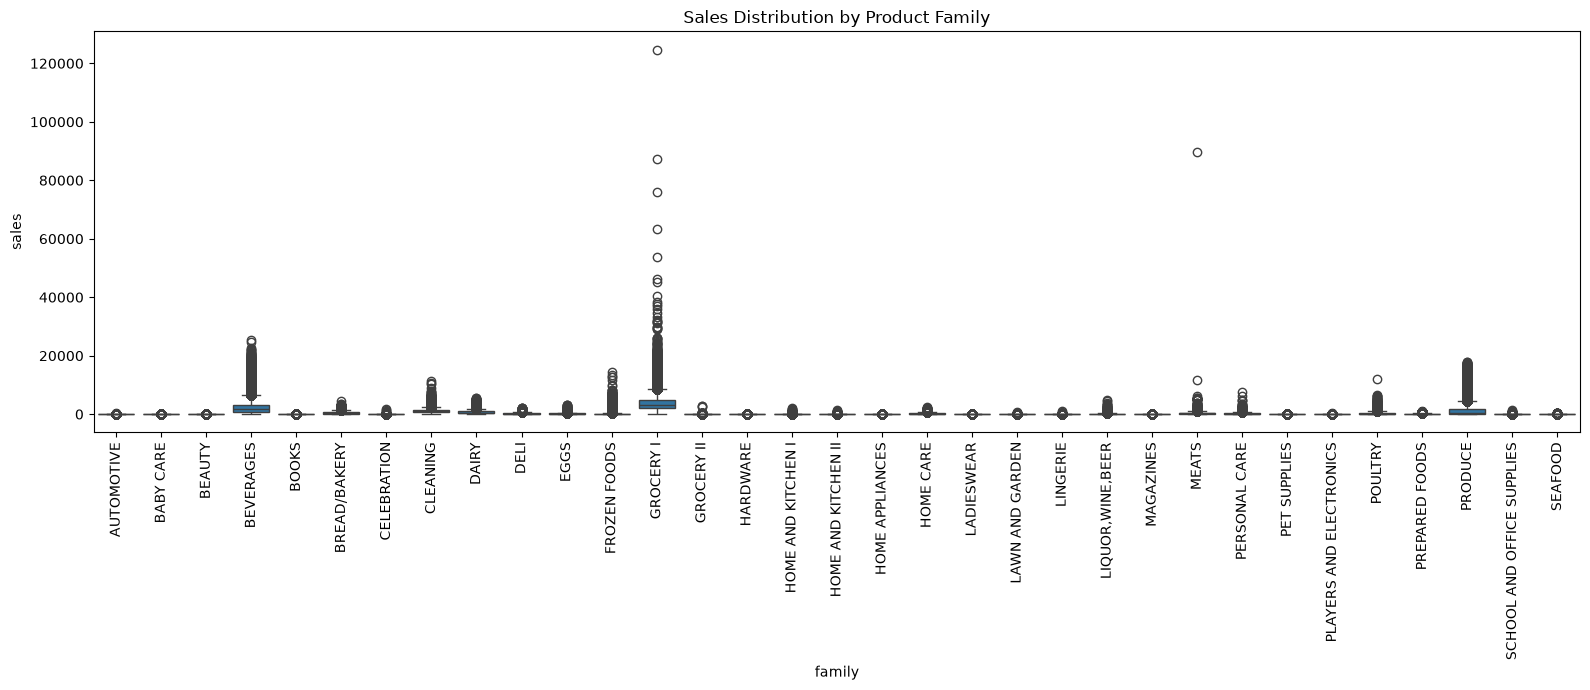

In [4]:
plt.figure(figsize=(16, 7))

sns.boxplot(data=df_full_train, x='family', y='sales')

plt.xticks(rotation=90)
plt.title('Sales Distribution by Product Family')
plt.tight_layout()
plt.show()

In [5]:
df_full_train

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.000,0
1,1,2013-01-01,1,BABY CARE,0.000,0
2,2,2013-01-01,1,BEAUTY,0.000,0
3,3,2013-01-01,1,BEVERAGES,0.000,0
4,4,2013-01-01,1,BOOKS,0.000,0
...,...,...,...,...,...,...
3000883,3000883,2017-08-15,9,POULTRY,438.133,0
3000884,3000884,2017-08-15,9,PREPARED FOODS,154.553,1
3000885,3000885,2017-08-15,9,PRODUCE,2419.729,148
3000886,3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,8


In [6]:
def remove_outliers(group):
    Q1 = group['sales'].quantile(0.25)
    Q3 = group['sales'].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    return group[
        (group['sales'] >= lower_bound) &
        (group['sales'] <= upper_bound)
    ]
# not necessary because tree are non-sensitive to outliers

# df_full_train = (
#     df_full_train
#     .groupby('family', group_keys=False)
#     .transform(remove_outliers)
#     .reset_index(drop=True)
# )

KeyError: 'sales'

In [ ]:
# 

In [ ]:

# df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
# df_train, df_val = train_test_split(
#     df_full_train, test_size=0.25, random_state=1
# )S
# df_train = df_train.reset_index(drop=True)
# df_val = df_val.reset_index(drop=True)
# df_test = df_test.reset_index(drop=True)

# y_train = (df_train['fuel_efficiency_mpg']).astype('float').values
# y_val = (df_val['fuel_efficiency_mpg']).astype('float').values
# y_test = (df_test['fuel_efficiency_mpg']).astype('float').values

In [ ]:
# Dictvectorizer
train_dicts = df_train.fillna(0).to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
dv.get_feature_names_out()

val_dicts = df_val.fillna(0).to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_val = dv.fit_transform(val_dicts)
dv.get_feature_names_out()

In [ ]:
# possible models, parameter tuning, evaluation (roc-auc curve, specified)

In [ ]:
# decision tree
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

y_pred = dt.predict(X_train)
# auc = roc_auc_score(y_train, y_pred)
# print('train:', auc)

y_pred = dt.predict(X_val)
# auc = roc_auc_score(y_val, y_pred)
# print('val:', auc)

from sklearn.tree import export_text
print(export_text(dt, feature_names=dv.get_feature_names_out()))

In [ ]:
######## Ensemble learning ##########

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

scores = []
n_estimators = [10, 50, 100, 150]
max_depths = [10, 15, 20, 25]

for max_depth in max_depths:
    for estimator in n_estimators:
        
        rf = RandomForestRegressor(n_estimators=estimator, random_state=1, n_jobs=-1, max_depth=max_depth)
        rf.fit(X_train, y_train)
        
        y_pred = rf.predict(X_val)
        
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        scores.append((max_depth, estimator, round(float(rmse), 5)))

columns = ['max_depth', 'estimator', 'rmse']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores.groupby('max_depth').mean()


In [ ]:
dt = RandomForestRegressor(max_depth=20, n_estimators=10, random_state=1, n_jobs=-1)
dt.fit(X_train, y_train)

y_pred = dt.predict(X_train)
# auc = roc_auc_score(y_train, y_pred)
# print('train:', auc)

y_pred = dt.predict(X_val)
# auc = roc_auc_score(y_val, y_pred)
# print('val:', auc)

importances = dt.feature_importances_
feature_names = dv.get_feature_names_out()

df_importances = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

print(df_importances)

In [ ]:
####### xgboost ##########
import sys
!{sys.executable} -m pip install xgboost
import xgboost as xgb

In [ ]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features) # DMatrix instead of numpy
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [ ]:
%%capture outputtt
watchlist = [(dtrain, 'train'), (dval, 'val')]

xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                  verbose_eval=5,
                  evals=watchlist)

In [ ]:
print(outputtt.stdout)

In [ ]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_rmse', 'val_rmse']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

df_score_three = parse_xgb_output(outputt)
df_score_one = parse_xgb_output(outputtt)

# over fitting (gap)
plt.plot(df_score_three.num_iter, df_score_three.train_rmse, label='train3')
plt.plot(df_score_three.num_iter, df_score_three.val_rmse, label='val3')
plt.plot(df_score_one.num_iter, df_score_one.train_rmse, label='train1')
plt.plot(df_score_one.num_iter, df_score_one.val_rmse, label='val1')
plt.legend()